# Estimación de la posición: de las pseudodistancias a X, Y, Z y el reloj del receptor

Este cuaderno continúa `gnss_pseudodistancia.ipynb`. Allí se dedujo la ecuación de la pseudodistancia y, con la posición de la estación conocida, se estimó el desfase del reloj del receptor. Aquí la posición es la incógnita: con las pseudodistancias reales de la estación **KOUR** (Kourou, Guayana Francesa, red IGS) del 15 de septiembre de 2026 se calcula, paso a paso, dónde está el receptor: linealización, mínimos cuadrados, iteración, selección de los mejores satélites por elevación, ponderación, covarianza y DOP. Cada resultado se compara con la posición de referencia de la estación.

**Datos.** La sección 0 de `gnss_pseudodistancia.ipynb` lee los archivos RINEX y guarda dos archivos en `data/`, con el nombre de la estación y la fecha (para KOUR el 15 de septiembre de 2026, `kour_20260915_…`):

- `…_gps.csv`: la tabla `D`, una fila por época y satélite GPS: `P1` (pseudodistancia con el código C/A en L1, m), `xs, ys, zs` (posición del satélite en el instante de emisión, m), `dts` (desfase del reloj del satélite, $\delta t^s$, ya ajustado con su retardo de grupo $T_{GD}$, s), `el`, `az` (elevación y acimut desde KOUR, grados), más `P2`, `L1` y `S1`, que aquí no se usan.
- `…_estacion.txt`: la **posición de referencia** de la estación. En este cuaderno es la del encabezado RINEX (`APPROX POSITION XYZ`), la misma que `gnss_pseudodistancia.ipynb` usa como posición conocida; no es la posición precisa que publica el IGS. Es aproximada, al metro o mejor, así que errores de menos de un metro no se pueden juzgar con ella.

Las columnas `xs, ys, zs`, `el` y `az` se calcularon en `gnss_pseudodistancia.ipynb` con esa posición: la rotación de la Tierra durante el viaje de la señal y la dirección de cada satélite dependen de dónde está el receptor. Un receptor que no conoce su posición las recalcula en cada iteración. Aquí se toman de la tabla, porque un error de decenas de metros en la posición cambia la corrección por rotación en menos de un milímetro y la elevación en milésimas de grado.

Para procesar otra estación u otro día: cambiar `ESTACION`, `FECHA` y `HORA` en la celda de la sección 0, con los mismos valores usados en `gnss_pseudodistancia.ipynb`.

**Notación.** La misma de `gnss_pseudodistancia.ipynb` (tabla de su sección 0):

| símbolo | qué es |
|---|---|
| $P1_i$ | pseudodistancia medida al satélite $i$ con el código C/A en L1 ($P_i$ en la sección 12 de `gnss_pseudodistancia.ipynb`) |
| $(X, Y, Z)$ | posición del receptor: las incógnitas |
| $(x^s_i, y^s_i, z^s_i)$ | posición del satélite $i$ en el instante de emisión |
| $r_i$ | distancia geométrica entre el receptor y el satélite $i$ |
| $c\,\delta t_R$ | desfase del reloj del receptor, en metros: la cuarta incógnita |
| $c\,\delta t^s_i$ | desfase del reloj del satélite $i$, en metros; lo transmite el satélite |
| $T_i$, $I_i$ | retardos troposférico e ionosférico; aquí no se modelan |
| $\varepsilon_i$ | lo que no se modela: ruido, multitrayectoria y, en este cuaderno, también $T_i + I_i$ |

Cada sección sigue el mismo patrón: una definición, las ecuaciones paso a paso, el cálculo con los datos y, cuando ayuda, una figura con su lectura.


In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
AZUL, ROJO, VERDE, GRIS, NARANJA = "#1F3864", "#9C0006", "#375623", "#7F7F7F", "#C55A11"

# velocidad de la luz en el vacío (m/s): valor exacto, porque define el metro en el SI
C = 299792458.0

## 0. Datos: la tabla de `gnss_pseudodistancia.ipynb`

Se leen la tabla `D` y la posición de referencia que guardó la sección 0 de `gnss_pseudodistancia.ipynb`. `ESTACION`, `FECHA` y `HORA` deben ser los mismos que allí; `HORA` es la época que se estudia en detalle, y `SAT`, el satélite que se usa de ejemplo en la sección 4.

In [2]:
# ── qué estación, qué día y qué época: los mismos valores que en gnss_pseudodistancia.ipynb ──
ESTACION = "KOUR00GUF" #"BOGT00COL"      # nombre IGS de 9 caracteres
FECHA = "2026-09-15"        # día de los archivos (UTC)
HORA = "12:00:00"           # la época que se estudia en detalle (tiempo GPS)
SAT = "G15"                 # satélite de ejemplo (debe estar visible a esa HORA)

prefijo = f"{ESTACION[:4].lower()}_{FECHA.replace('-', '')}"

# la tabla D de gnss_pseudodistancia.ipynb (sección 0): una fila por época y satélite GPS
D = pd.read_csv(f"data/{prefijo}_gps.csv", parse_dates=["t"])

# la posición de referencia de la estación: la aproximada del encabezado RINEX (X, Y, Z geocéntricas, m)
lineas = open(f"data/{prefijo}_estacion.txt").read().splitlines()[1:]
est = dict(linea.split() for linea in lineas)
rx = np.array([float(est["X"]), float(est["Y"]), float(est["Z"])])

print("filas:", len(D), "| épocas:", D.t.nunique(), "| satélites distintos:", D.sv.nunique())
print(f"{ESTACION[:4]}, posición de referencia (X, Y, Z) =", rx)
D.head()

# ── selección de satélites para la solución ──
# de todos los satélites visibles se conservan los N_MEJORES con mayor elevación
# (cuatro es el mínimo para resolver; más satélites mejoran la geometría)
N_MEJORES = 8
assert N_MEJORES >= 4, "se necesitan al menos 4 satélites para resolver posición y reloj"


filas: 34499 | épocas: 2880 | satélites distintos: 32
KOUR, posición de referencia (X, Y, Z) = [ 3839591.4332 -5059567.5514   579956.9164]


## 1. Planteamiento: ecuaciones de observación y cuatro incógnitas

Se parte de la ecuación de la pseudodistancia de `gnss_pseudodistancia.ipynb`, para el satélite $i$:
$$P1_i = r_i + c\,\delta t_R - c\,\delta t^s_i + T_i + I_i + \varepsilon_i$$
Allí la posición de la estación era conocida y $r_i$ era un dato. Aquí no: $r_i$ depende de las incógnitas.

| término | ¿se conoce? | por qué |
|---|---|---|
| $P1_i$ | sí | lo midió el receptor |
| $c\,\delta t^s_i$ | sí | lo transmite el satélite (columna `dts`) |
| $x^s_i, y^s_i, z^s_i$ | sí | se calculan con las efemérides |
| $X, Y, Z$ | **no** | es lo que se busca |
| $c\,\delta t_R$ | **no** | es la cuarta incógnita |
| $T_i$, $I_i$ | no se modelan | se dejan dentro de $\varepsilon_i$; la sección 9 muestra su efecto |

Pasando lo conocido a la izquierda:
$$\underbrace{P1_i + c\,\delta t^s_i}_{\text{medida corregida}} = \underbrace{\sqrt{(X - x^s_i)^2 + (Y - y^s_i)^2 + (Z - z^s_i)^2}}_{r_i(X,\,Y,\,Z)} + c\,\delta t_R + \varepsilon_i$$
Es la ecuación de la sección 12 de `gnss_pseudodistancia.ipynb`, sin los términos de atmósfera. Hay una por satélite (once visibles a las 12:00 en esta estación, de los que se usan los ocho más altos) y cuatro incógnitas. La raíz cuadrada impide despejar, y con ocho ecuaciones y ruido no existe un $(X, Y, Z, c\,\delta t_R)$ que las cumpla todas. Hace falta (1) un método que se acerque a la solución paso a paso y (2) un criterio para elegir la «mejor» cuando ninguna es exacta.


In [3]:
t0 = pd.Timestamp(f"{FECHA} {HORA}")              # la época de trabajo (tiempo GPS)
assert SAT in set(D.sv[D.t == t0]), f"{SAT} no está visible a las {HORA}"
ep_todos = D[D.t == t0].sort_values("sv").reset_index(drop=True)

S_todos = ep_todos[["xs", "ys", "zs"]].values   # posiciones de todos los satélites visibles (n × 3, m)
P_todos = ep_todos.P1.values + C * ep_todos.dts.values   # medida corregida P1 + c·δtˢ de todos (m)
n_todos = len(P_todos)

def mejores_por_elevacion(g, k=N_MEJORES):
    """Devuelve las k filas de g con mayor elevación (todas si g tiene menos de k)."""
    return g.loc[g.el.nlargest(min(k, len(g))).index]

# la solución se calcula solo con los N_MEJORES satélites más altos
ep = mejores_por_elevacion(ep_todos).sort_values("sv").reset_index(drop=True)
S = ep[["xs", "ys", "zs"]].values           # posiciones de los satélites seleccionados: matriz n × 3 (m)
P = ep.P1.values + C * ep.dts.values         # medida corregida P1 + c·δtˢ (m)
n = len(P)

tabla = ep_todos[["sv", "el", "P1"]].copy()
tabla.insert(0, "rango por elevación", tabla.el.rank(ascending=False, method="min").astype(int))
tabla["c·δtˢ (m)"] = C * ep_todos.dts
tabla["P1 + c·δtˢ (m)"] = P_todos
tabla["usado"] = tabla.sv.isin(ep.sv)
print(f"satélites visibles: {list(ep_todos.sv)} | n = {n_todos}")
print(f"seleccionados (los {n} de mayor elevación): {list(ep.sv)}")
print(f"elevaciones usadas: {ep.el.round(1).tolist()}°")
tabla.round(3)


satélites visibles: ['G05', 'G06', 'G11', 'G12', 'G13', 'G15', 'G20', 'G21', 'G24', 'G29', 'G30'] | n = 11
seleccionados (los 8 de mayor elevación): ['G05', 'G06', 'G11', 'G15', 'G20', 'G21', 'G24', 'G29']
elevaciones usadas: [27.0, 25.2, 55.0, 46.1, 50.3, 21.6, 40.1, 26.6]°


,rango por elevación,sv,el,P1,c·δtˢ (m),P1 + c·δtˢ (m),usado
0,5,G05,27.031,2.293802e+07,-70984.934,2.286704e+07,True
1,7,G06,25.162,2.337821e+07,-156510.771,2.322170e+07,True
2,1,G11,54.978,2.106077e+07,-62718.618,2.099805e+07,True
3,9,G12,12.549,2.478722e+07,-180485.335,2.460673e+07,False
4,11,G13,11.845,2.438745e+07,132652.265,2.452011e+07,False
5,3,G15,46.081,2.125670e+07,133372.634,2.139007e+07,True
6,2,G20,50.336,2.125397e+07,85762.858,2.133973e+07,True
7,8,G21,21.553,2.341803e+07,108560.613,2.352659e+07,True
8,4,G24,40.140,2.206127e+07,62539.257,2.212381e+07,True
9,6,G29,26.581,2.302816e+07,-72763.214,2.295539e+07,True


## 1.1 Selección de los mejores satélites por elevación

Antes de resolver se eligen los satélites que entran en la solución. El criterio es la **elevación**: cuanto más alto está un satélite, menos atmósfera atraviesa su señal y menos ruido y multitrayecto recibe (secciones 9 y 10). Por eso se ordenan los visibles por elevación y se conservan los `N_MEJORES` más altos (`N_MEJORES = 8` en la sección 0).

Con menos de cuatro satélites no habría solución; los que quedan fuera de la selección siguen en `ep_todos` y se usan solo para comparar y para los diagnósticos. La columna `usado` de la tabla anterior marca cuáles entraron en el ajuste.


## 2. Valor inicial: el receptor en el centro de la Tierra

Se supone que el receptor arranca en $(0, 0, 0)$ con su reloj sin desfase ($c\,\delta t_R = 0$). Desde ahí, la distancia calculada a cada satélite es su radio orbital. La diferencia entre lo medido y lo calculado se llama **observado menos calculado** ($O - C$). Aquí es de miles de kilómetros, y es la información con la que se trabaja: dice hacia dónde y cuánto mover la posición supuesta.


In [4]:
x0 = np.zeros(4)                                  # posición supuesta (X, Y, Z) = (0, 0, 0) y c·δt_R = 0
r0 = np.linalg.norm(S - x0[:3], axis=1)          # distancia de cada satélite a la posición supuesta
dP = P - (r0 + x0[3])                             # O − C: lo que la posición supuesta no explica de cada medida

pd.DataFrame({"sv": ep.sv,
              "P1 + c·δtˢ (km)": P / 1e3,
              "calculada desde (0, 0, 0) (km)": r0 / 1e3,
              "O − C (km)": dP / 1e3}).round(1)


,sv,P1 + c·δtˢ (km),"calculada desde (0, 0, 0) (km)",O − C (km)
0,G05,22867.0,26418.7,-3551.6
1,G06,23221.7,26607.1,-3385.4
2,G11,20998.1,26513.3,-5515.2
3,G15,21390.1,26394.8,-5004.8
4,G20,21339.7,26598.9,-5259.2
5,G21,23526.6,26575.7,-3049.1
6,G24,22123.8,26724.4,-4600.6
7,G29,22955.4,26467.8,-3512.4


## 3. Método de Newton-Raphson en una dimensión

> **Newton-Raphson** — para hallar $x$ tal que $f(x) = 0$, desde una estimación $x_k$ se sustituye la curva por su recta tangente y se toma el cruce de la tangente con el eje como estimación siguiente:
> $$x_{k+1} = x_k - \frac{f(x_k)}{f'(x_k)}$$

Cada paso se acerca más a la raíz y, cerca de ella, aproximadamente duplica el número de cifras correctas. Con cuatro incógnitas la «tangente» es un hiperplano en cuatro dimensiones, pero la mecánica es idéntica: **evaluar, derivar, corregir, repetir**.

In [5]:
def f(x):  return x**3 - x - 1        # la función cuya raíz se busca
def df(x): return 3 * x**2 - 1        # su derivada

xk = 1.0                              # estimación inicial
filas = []
for k in range(1, 6):
    x_siguiente = xk - f(xk) / df(xk)                    # el paso de Newton-Raphson
    filas.append(dict(k=k, x_k=xk, f=f(xk), df=df(xk), x_siguiente=x_siguiente))
    xk = x_siguiente
pd.DataFrame(filas).round(7)

,k,x_k,f,df,x_siguiente
0,1,1.000000,-1.000000e+00,2.000000,1.500000
1,2,1.500000,8.750000e-01,5.750000,1.347826
2,3,1.347826,1.006822e-01,4.449905,1.325200
3,4,1.325200,2.058400e-03,4.268468,1.324718
4,5,1.324718,9.000000e-07,4.264635,1.324718


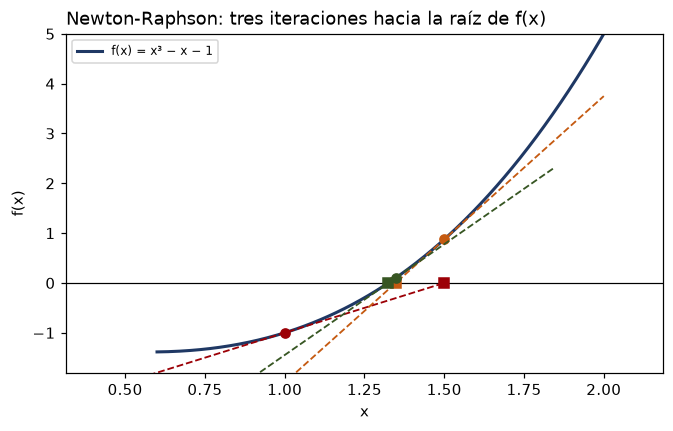

In [6]:
x_graf = np.linspace(0.6, 2.1, 300)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x_graf, f(x_graf), color=AZUL, lw=2, label="f(x) = x³ − x − 1")
ax.axhline(0, color="k", lw=0.8)

xk = 1.0
for color in [ROJO, NARANJA, VERDE]:
    xt = np.linspace(xk - 0.6, xk + 0.5, 50)
    ax.plot(xt, f(xk) + df(xk) * (xt - xk), "--", color=color, lw=1.2)   # la recta tangente en xk
    ax.plot(xk, f(xk), "o", color=color)                                  # el punto sobre la curva
    xk = xk - f(xk) / df(xk)                                              # el cruce de la tangente con el eje
    ax.plot(xk, 0, "s", color=color)
ax.set_ylim(-1.8, 5)
ax.set_xlabel("x")
ax.set_ylabel("f(x)")
ax.legend(fontsize=8)
ax.set_title("Newton-Raphson: tres iteraciones hacia la raíz de f(x)", loc="left");

## 4. Linealización: vector unitario del receptor al satélite

> Si el receptor está en una posición aproximada $\mathbf{X}_0$ y la verdadera es $\mathbf{X}_0 + \Delta\mathbf{X}$, la distancia a un satélite en $\mathbf{x}^s$, desarrollada en **serie de Taylor a primer orden**, es
> $$r(\mathbf{X}) \approx r_0 - \mathbf{e}\cdot\Delta\mathbf{X}, \qquad \mathbf{e} = \frac{\mathbf{x}^s - \mathbf{X}_0}{r_0}$$
> $\mathbf{e}$ es el **vector unitario** del receptor hacia el satélite; sus componentes son las derivadas de la distancia respecto a $X, Y, Z$, con signo menos. Moverse 1 m hacia el satélite acorta la distancia 1 m; moverse en perpendicular no la cambia.


In [7]:
def vectores_unitarios(x, S):
    """Desde la posición x = (X, Y, Z, c·δt_R): distancias r a cada satélite y vectores unitarios e hacia cada uno."""
    r = np.linalg.norm(S - x[:3], axis=1)   # distancia a cada satélite (n)
    e = (S - x[:3]) / r[:, None]             # (satélite − receptor) / distancia: longitud 1 (n × 3)
    return e, r

# el ejemplo usa todos los visibles para poder dibujar cualquier SAT, no solo los seleccionados
e, r = vectores_unitarios(np.r_[rx, 0.0], S_todos)
i_sat = list(ep_todos.sv).index(SAT)
print(f"e({SAT}) =", e[i_sat].round(4), "| longitud =", np.linalg.norm(e[i_sat]).round(6), "| r0 =", f"{r[i_sat]:,.3f} m")


e(G15) = [-0.0951 -0.9437  0.3168] | longitud = 1.0 | r0 = 21,428,098.036 m


## 5. Matriz de diseño

Se sustituye la linealización en la ecuación de cada satélite y se pasa lo conocido a la izquierda. Para el satélite $i$, con la posición aproximada $\mathbf{X}_0$ y el reloj aproximado $c\,\delta t_{R,0}$:
$$\underbrace{P1_i + c\,\delta t^s_i - r_{0,i} - c\,\delta t_{R,0}}_{(O - C)_i} = -e_{X,i}\,\Delta X - e_{Y,i}\,\Delta Y - e_{Z,i}\,\Delta Z + \Delta(c\,\delta t_R)$$
El lado izquierdo es el **observado menos calculado** ($O - C$, o residuo previo al ajuste): la medida corregida menos lo que predice la posición aproximada. Si esa posición es la de referencia y $c\,\delta t_{R,0} = 0$, es exactamente el *residuo de pseudodistancia* de la sección 7 de `gnss_pseudodistancia.ipynb`.

> **Matriz de diseño $\mathbf{A}$** ($n \times 4$) — una fila por satélite: las tres componentes de su vector unitario con signo menos y un 1 para el reloj. El sistema lineal es $\mathbf{A}\,\Delta\mathbf{x} = \mathbf{O} - \mathbf{C}$, con incógnitas las **correcciones** $\Delta\mathbf{x} = \big(\Delta X, \Delta Y, \Delta Z, \Delta(c\,\delta t_R)\big)$.


In [8]:
def diseno(x, S, P):
    """Matriz de diseño A (n × 4) y vector O − C (dP, n) en la posición aproximada x = (X, Y, Z, c·δt_R).
    Fila i de A: (−e_X, −e_Y, −e_Z, 1). dP_i: medida corregida menos lo que predice x."""
    e, r = vectores_unitarios(x, S)
    A = np.hstack([-e, np.ones((len(P), 1))])
    dP = P - (r + x[3])
    return A, dP

A, dP = diseno(np.r_[rx, 0.0], S, P)
pd.DataFrame(A, index=ep.sv, columns=["−e_X", "−e_Y", "−e_Z", "1"]).round(4)

,−e_X,−e_Y,−e_Z,1
sv,,,,
G05,-0.2633,0.2661,-0.9273,1.0
G06,-0.8628,-0.0608,0.5019,1.0
G11,-0.9497,0.3130,0.0116,1.0
G15,0.0951,0.9437,-0.3168,1.0
G20,-0.3350,0.6360,-0.6952,1.0
G21,-0.6661,-0.1272,-0.7350,1.0
G24,-0.2870,0.6735,0.6812,1.0
G29,0.3881,0.8073,-0.4445,1.0


## 6. Mínimos cuadrados: criterio y ecuaciones normales

> **Sistema sobredeterminado** — más ecuaciones que incógnitas: en general ninguna $\Delta\mathbf{x}$ cumple todas. A cada satélite le queda un **residuo posterior al ajuste**, lo que la solución no explica:
> $$v_i = (O - C)_i - (\mathbf{A}\,\Delta\mathbf{x})_i$$
> El $O - C$ es el residuo *previo* al ajuste; $v_i$, el que queda *después*.
>
> **Mínimos cuadrados** (Legendre 1805, Gauss 1809) — elegir la $\Delta\mathbf{x}$ que hace mínima $\sum v_i^2$. Derivando e igualando a cero salen las **ecuaciones normales**:
> $$(\mathbf{A}^{\top}\mathbf{A})\,\Delta\mathbf{x} = \mathbf{A}^{\top}(\mathbf{O} - \mathbf{C}) \quad\Rightarrow\quad \Delta\mathbf{x} = (\mathbf{A}^{\top}\mathbf{A})^{-1}\mathbf{A}^{\top}(\mathbf{O} - \mathbf{C})$$

La suma de cuadrados es una parábola en cada incógnita, y el mínimo está donde la pendiente es cero. La celda siguiente hace un solo paso, partiendo de la posición de referencia. Como esa posición ya está a pocos metros de la solución, la linealización es casi exacta: la corrección dice directamente cuánto se aparta la solución de la posición de referencia, y la sección 7 confirma que iterar no la cambia.


In [9]:
def paso_minimos_cuadrados(A, dP, W=None):
    """Resuelve las ecuaciones normales (AᵀWA) Δx = AᵀW dP. Sin W, todos los pesos valen 1.
    Devuelve la corrección Δx, la matriz normal N = AᵀWA y su inversa (la matriz cofactor Q)."""
    if W is None:
        W = np.eye(len(dP))
    N = A.T @ W @ A
    dx = np.linalg.solve(N, A.T @ W @ dP)
    return dx, N, np.linalg.inv(N)

dx, N, Q = paso_minimos_cuadrados(A, dP)
print("AᵀA =\n", N.round(3))
print("\ncorrección Δx = (ΔX, ΔY, ΔZ, Δ(c·δt_R)) en metros:", dx.round(3))

AᵀA =
 [[ 2.514 -0.233  0.124 -2.881]
 [-0.233  2.589 -0.821  3.452]
 [ 0.124 -0.821  2.897 -1.924]
 [-2.881  3.452 -1.924  8.   ]]

corrección Δx = (ΔX, ΔY, ΔZ, Δ(c·δt_R)) en metros: [ 6.7430000e+00 -1.2012000e+01  3.0410000e+00 -3.8013891e+04]


## 7. Solución iterativa: Gauss-Newton

Se parte del centro de la Tierra. En cada iteración se linealiza en la posición supuesta, se resuelven las ecuaciones normales y se suma la corrección. Se detiene cuando la corrección es despreciable (aquí, menor que 0,1 mm). Este esquema —Newton-Raphson aplicado a mínimos cuadrados— se llama **Gauss-Newton**.

In [10]:
def resolver(S, P, x0=None, W=None, tol=1e-4, maxit=20):
    """Mínimos cuadrados iterados (Gauss-Newton) para la posición del receptor.
    S: posiciones de los satélites (n × 3) · P: medidas corregidas P1 + c·δtˢ (n)
    x0: posición inicial (X, Y, Z, c·δt_R); por defecto el centro de la Tierra · W: matriz de pesos (n × n)
    tol: se detiene cuando la corrección es menor (m) · Devuelve x, A final, residuos v, Q = (AᵀWA)⁻¹ y el historial."""
    x = np.zeros(4) if x0 is None else np.array(x0, float)
    if W is None:
        W = np.eye(len(P))
    historial = []
    for k in range(1, maxit + 1):
        A, dP = diseno(x, S, P)                            # 1. linealizar en la posición actual
        dx, N, Q = paso_minimos_cuadrados(A, dP, W)         # 2. resolver las ecuaciones normales
        historial.append(dict(iteracion=k, correccion_m=np.linalg.norm(dx[:3]), rms_O_menos_C_m=np.sqrt(np.mean(dP**2))))
        x = x + dx                                          # 3. corregir
        if np.linalg.norm(dx) < tol:                        # 4. repetir hasta que la corrección sea despreciable
            break
    A, v = diseno(x, S, P)                                  # residuos finales: lo que la solución no explica
    Q = np.linalg.inv(A.T @ W @ A)
    return x, A, v, Q, pd.DataFrame(historial)

x, A, v, Q, hist = resolver(S, P)
m3 = lambda v: f"{v:,.3f}".replace(",", " ")              # metros con espacio de miles
print(f"solución (X, Y, Z)      = ({m3(x[0])}; {m3(x[1])}; {m3(x[2])}) m | c·δt_R = {x[3]:.3f} m")
print(f"posición de referencia  = ({m3(rx[0])}; {m3(rx[1])}; {m3(rx[2])}) m")
print("diferencia X, Y, Z (m)  =", (x[:3] - rx).round(3))
hist.round(4)

solución (X, Y, Z)      = (3 839 598.176; -5 059 579.563; 579 959.958) m | c·δt_R = -38013.891 m
posición de referencia  = (3 839 591.433; -5 059 567.551; 579 956.916) m
diferencia X, Y, Z (m)  = [  6.743 -12.012   3.041]


,iteracion,correccion_m,rms_O_menos_C_m
0,1,7.617759e+06,4.330112e+06
1,2,1.205098e+06,6.525689e+05
2,3,3.485920e+04,2.235442e+04
3,4,3.001870e+01,1.767290e+01
4,5,0.000000e+00,4.150000e-01


desde centro de la Tierra     : 5 iteraciones, misma solución a 0.0000 m
desde un punto a 290 km       : 4 iteraciones, misma solución a 0.0000 m
desde antípoda de la estación : 6 iteraciones, misma solución a 0.0000 m


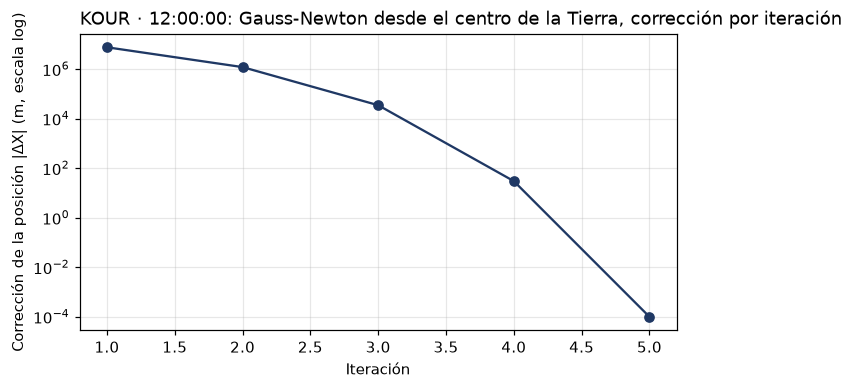

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.semilogy(hist.iteracion, hist.correccion_m.clip(1e-4), "o-", color=AZUL)
ax.set_xlabel("Iteración")
ax.set_ylabel("Corrección de la posición |ΔX| (m, escala log)")
ax.grid(alpha=0.3, which="both")
ax.set_title(f"{ESTACION[:4]} · {HORA}: Gauss-Newton desde el centro de la Tierra, corrección por iteración", loc="left")

# ¿depende del punto de partida? tres semillas muy distintas
semillas = [(np.zeros(3), "centro de la Tierra"),
            (rx + np.array([1.5e5, -1.5e5, 2e5]), "un punto a 290 km"),
            (-rx, "antípoda de la estación")]
for semilla, nombre in semillas:
    x_s, _, _, _, h_s = resolver(S, P, x0=np.r_[semilla, 0.0])
    print(f"desde {nombre:<24}: {len(h_s)} iteraciones, misma solución a {np.linalg.norm(x_s[:3] - x[:3]):.4f} m")

Desde el centro de la Tierra, la primera corrección mueve la posición unos 7 618 km; la segunda, 1 205 km; la tercera, 34,9 km; la cuarta, 30 m, y la quinta, menos de un milímetro. La corrección cae varios órdenes de magnitud por iteración, como en Newton-Raphson (sección 3). Desde tres puntos de partida muy distintos (el centro de la Tierra, un punto a 290 km de la estación y su antípoda) se llega a la misma solución en 4 a 6 iteraciones.


## 8. Error de la solución en el sistema local Este-Norte-Arriba

> **Sistema local ENU** — en el punto de la estación: **Este** y **Norte** tangentes al elipsoide, **Arriba** normal a él. El error de una solución se expresa girando la diferencia $(\mathbf{X} - \mathbf{X}_{\text{ref}})$ desde X, Y, Z a este sistema, con la matriz de rotación que depende de la latitud $\varphi$ y la longitud $\lambda$:
> $$\mathbf{R} = \begin{bmatrix} -\sin\lambda & \cos\lambda & 0 \\ -\sin\varphi\cos\lambda & -\sin\varphi\sin\lambda & \cos\varphi \\ \cos\varphi\cos\lambda & \cos\varphi\sin\lambda & \sin\varphi \end{bmatrix}$$


In [12]:
def xyz_a_geodesicas(X, Y, Z, a=6378137.0, f=1/298.257223563):
    """Coordenadas geocéntricas (m) -> latitud y longitud (grados) y altura elipsoidal (m).
    a, f: semieje mayor y aplanamiento del elipsoide (WGS84). Iteración clásica sobre la latitud (igual que en gnss_pseudodistancia)."""
    e2 = f * (2 - f)                       # excentricidad al cuadrado
    lon = np.arctan2(Y, X)                 # la longitud sale directa
    p = np.hypot(X, Y)                     # distancia al eje de rotación
    lat = np.arctan2(Z, p * (1 - e2))      # primera aproximación de la latitud
    for _ in range(10):                    # se refina la latitud (converge en pocas vueltas)
        N = a / np.sqrt(1 - e2 * np.sin(lat) ** 2)     # radio de curvatura en el primer vertical
        h = p / np.cos(lat) - N                         # altura sobre el elipsoide
        lat = np.arctan2(Z, p * (1 - e2 * N / (N + h)))
    return np.degrees(lat), np.degrees(lon), h

lat_est, lon_est, h_est = xyz_a_geodesicas(*rx)     # latitud y longitud (grados) y altura elipsoidal (m) de la estación
la, lo = np.radians([lat_est, lon_est])
# matriz de rotación de (X, Y, Z) a (Este, Norte, Arriba) en la estación
Rm = np.array([[-np.sin(lo),              np.cos(lo),              0],
               [-np.sin(la) * np.cos(lo), -np.sin(la) * np.sin(lo), np.cos(la)],
               [ np.cos(la) * np.cos(lo),  np.cos(la) * np.sin(lo), np.sin(la)]])

def enu(x):
    """Error de la solución x respecto a la posición de referencia, en metros hacia el Este, el Norte y Arriba."""
    return Rm @ (x[:3] - rx)

E_, N_, U_ = enu(x)
print(f"error a las {HORA}: {E_:+.2f} m Este, {N_:+.2f} m Norte, {U_:+.2f} m Arriba | c·δt_R = {x[3]:.2f} m = {x[3]/C*1e9:.0f} ns")


error a las 12:00:00: -1.89 m Este, +1.78 m Norte, +13.87 m Arriba | c·δt_R = -38013.89 m = -126801 ns


La solución de las 12:00, calculada con los ocho satélites de mayor elevación, queda −1,89 m al Este y +1,78 m al Norte de la posición de referencia, y +13,87 m más arriba. El error horizontal es del orden de la exactitud de esa posición aproximada (al metro); el vertical no. El reloj sale $c\,\delta t_R = -38\,013{,}9$ m (−126 801 ns). En `gnss_pseudodistancia.ipynb` (sección 7), con la posición fija, el reloj estimado era otro: la diferencia no es un error de cálculo. Con la posición libre, la parte de la atmósfera no modelada que cambia con la elevación se reparte entre la altura y el reloj, que están muy correlacionados (0,96 en esta época; sección 11). La sección 9 lo explica.


## 9. Solución en las 2 880 épocas: precisión, sesgo y control de calidad

Repitiendo la solución en cada época se ven la **precisión** (la dispersión de los errores) y el **sesgo** (el error sistemático). Antes hay que revisar los residuos de cada época. La desviación típica estimada de una medida es
$$\hat\sigma_0 = \sqrt{\frac{\mathbf{v}^{\top}\mathbf{v}}{n - 4}}$$
donde $n - 4$ son los grados de libertad: las medidas que sobran después de determinar las cuatro incógnitas. Si en alguna época sale de kilómetros, alguna medida está mal.


In [13]:
filas = []
for t, g in D.groupby("t"):                       # una solución por época
    g = mejores_por_elevacion(g)                  # solo los N_MEJORES satélites por elevación
    if len(g) < 4:
        continue                                   # con menos de 4 satélites no hay solución
    S_ = g[["xs", "ys", "zs"]].values
    P_ = g.P1.values + C * g.dts.values
    x_, A_, v_, Q_, h_ = resolver(S_, P_)
    e_ = enu(x_)
    sigma0_ = np.sqrt(v_ @ v_ / (len(v_) - 4))    # desviación típica estimada de una medida
    filas.append(dict(t=t, n=len(g), E=e_[0], N=e_[1], U=e_[2], c_dtR=x_[3], sigma0=sigma0_, iteraciones=len(h_)))
sol = pd.DataFrame(filas).set_index("t")

malas = sol[sol.sigma0 > 100]                     # control de calidad: épocas con residuos absurdos
print("épocas con sigma0 > 100 m:", len(malas))
print(malas.round(1))


épocas con sigma0 > 100 m: 0
Empty DataFrame
Columns: [n, E, N, U, c_dtR, sigma0, iteraciones]
Index: []


In [14]:
for t_mala in malas.index:
    g = D[D.t == t_mala]
    r_geom = np.linalg.norm(g[["xs", "ys", "zs"]].values - rx, axis=1)     # distancia geométrica desde la posición de referencia
    res = g.P1.values + C * g.dts.values - r_geom                          # P1 + c·δtˢ − r: el residuo de gnss_pseudodistancia (sección 7)
    print(t_mala)
    print(pd.DataFrame({"sv": g.sv, "P1 (km)": g.P1 / 1e3, "P1 + c·δtˢ − r (km)": res / 1e3}).round(1).to_string(index=False))
    for _, m in g[(g.P1 < 1.9e7) | (g.P1 > 2.7e7)].iterrows():              # fuera del rango posible para un satélite GPS
        print(f"\n{m.sv}: una pseudodistancia de {m.P1/1e3:,.0f} km es imposible (los satélites GPS están entre 20 000 y 26 000 km): esa época se descarta.".replace(",", " "))
epocas_malas = set(malas.index)                   # se excluyen también en las secciones 10 y 12
sol = sol[sol.sigma0 <= 100]

Con esta estación y este día no hay épocas con $\hat\sigma_0 > 100$ m: las 2 880 soluciones quedan dentro de un rango razonable. El control de calidad se mantiene porque en otras estaciones o días una sola medida mala —como la de G32 en la tabla de `gnss_pseudodistancia.ipynb`— puede arrastrar la solución de toda la época millones de metros. Los mínimos cuadrados no toleran valores atípicos; por eso los residuos se revisan antes de usar la solución.


2880 épocas | RMS horizontal 1.99 m | error en altura: media +14.9 m, RMS 15.7 m | sigma0 mediana 0.94 m


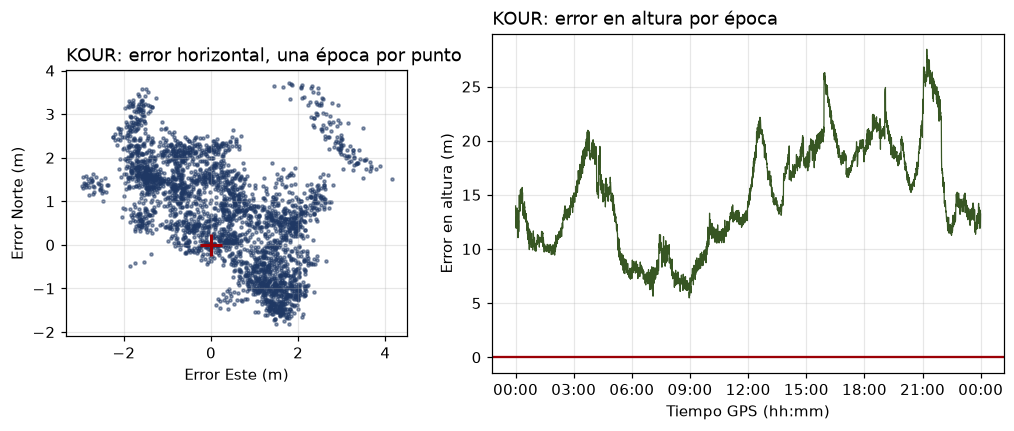

In [15]:
rms_h = np.sqrt((sol.E**2 + sol.N**2).mean())
print(f"{len(sol)} épocas | RMS horizontal {rms_h:.2f} m | error en altura: media {sol.U.mean():+.1f} m, RMS {np.sqrt((sol.U**2).mean()):.1f} m | sigma0 mediana {sol.sigma0.median():.2f} m")

fig, axs = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw=dict(width_ratios=[1, 1.5]))
axs[0].scatter(sol.E, sol.N, s=4, color=AZUL, alpha=0.5)
axs[0].plot(0, 0, "+", color=ROJO, ms=14, mew=2)
axs[0].set_aspect("equal")
axs[0].set_xlabel("Error Este (m)")
axs[0].set_ylabel("Error Norte (m)")
axs[0].set_title(f"{ESTACION[:4]}: error horizontal, una época por punto", loc="left")
axs[0].grid(alpha=0.3)
axs[1].plot(sol.index, sol.U, color=VERDE, lw=0.8)
axs[1].axhline(0, color=ROJO)
axs[1].set_ylabel("Error en altura (m)")
axs[1].set_xlabel("Tiempo GPS (hh:mm)")
axs[1].set_title(f"{ESTACION[:4]}: error en altura por época", loc="left")
axs[1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
axs[1].grid(alpha=0.3);

In [16]:
# por qué la altura sale arriba: la época de trabajo, resuelta con un retardo simulado en lugar de las medidas
# retardo troposférico en el cenit: unos 2,3 m a nivel del mar, menos en una estación alta (la presión cae con escala de unos 8 km)
T_cenit = 2.3 * np.exp(-h_est / 8000)
el_, az_ = np.radians(ep.el.values), np.radians(ep.az.values)
H = np.c_[-np.cos(el_) * np.sin(az_), -np.cos(el_) * np.cos(az_), -np.sin(el_), np.ones(n)]   # matriz de diseño en E, N, U y reloj
for nombre, retardo in [("igual en todos los satélites, 5 m", np.full(n, 5.0)),
                        (f"troposférico, {T_cenit:.1f} m / sin(elevación)".replace(".", ","), T_cenit / np.sin(el_))]:
    dE, dN, dU, d_reloj = np.linalg.lstsq(H, retardo, rcond=None)[0]
    print(f"retardo {nombre:<38} -> E {dE:+.2f}  N {dN:+.2f}  U {dU:+.2f}  c·δt_R {d_reloj:+.2f} m")


retardo igual en todos los satélites, 5 m      -> E +0.00  N +0.00  U +0.00  c·δt_R +5.00 m
retardo troposférico, 2,3 m / sin(elevación)   -> E -0.29  N -0.19  U +7.03  c·δt_R +8.36 m


**Cómo leer la figura.** El error horizontal (izquierda) se concentra alrededor de cero, con un RMS de 1,99 m, y crece ligeramente entre las 12:00 y las 14:00 y hacia las 21:00 de tiempo GPS. El error en altura (derecha) es siempre positivo: entre +5,5 y +28,4 m, con media +14,9 m. Es menor de madrugada y a media mañana (unos 5,5 m hacia las 09:00) y mayor por la tarde y la noche (unos 28 m hacia las 21:00): coincide con el ciclo diario de la ionosfera (`gnss_pseudodistancia.ipynb`, sección 10). La desviación típica de una medida, $\hat\sigma_0$, tiene mediana 0,94 m: el ruido es de un metro, pero el error en altura es más de diez veces mayor. No es ruido: es un sesgo.

La celda anterior explica de dónde sale. Resuelve la época de las 12:00 con un retardo simulado en lugar de las medidas. Un retardo igual para todos los satélites lo absorbe entero el reloj, y la posición no cambia. Pero la atmósfera no es igual para todos: crece cuando el satélite baja. Esa parte se parece a subir el receptor: al subir, las distancias a los satélites altos se acortan más que las de los bajos, así que, comparadas, las de los bajos quedan más largas, como si su señal llegara tarde. Con un retardo troposférico de $T_{\text{cenit}}/\sin(\text{elevación})$, la geometría de las 12:00 da +7,0 m en altura y +8,4 m en el reloj, casi sin mover la posición horizontal. $T_{\text{cenit}}$ se tomó de 2,3 m, el valor típico a nivel del mar, coherente con la altura de Kourou. La ionosfera, que con el satélite bajo puede llegar a varios metros, suma su parte. Por eso un receptor que no corrige la atmósfera se equivoca sobre todo en altura, y hacia arriba.


## 10. Mínimos cuadrados ponderados por elevación

Agrupando los residuos posteriores al ajuste de todas las soluciones del día por elevación, la dispersión crece hacia el horizonte. Tratar todas las medidas por igual es regalar influencia a las peores.

> **Mínimos cuadrados ponderados** — a cada medida se le da un peso $w_i \propto 1/\sigma_i^2$ y se minimiza $\sum w_i v_i^2$. Con $\mathbf{W} = \mathrm{diag}(w_i)$:
> $$\Delta\mathbf{x} = (\mathbf{A}^{\top}\mathbf{W}\mathbf{A})^{-1}\mathbf{A}^{\top}\mathbf{W}\,(\mathbf{O} - \mathbf{C}), \qquad \hat\sigma_0^2 = \frac{\mathbf{v}^{\top}\mathbf{W}\mathbf{v}}{n-4}$$
> Un modelo habitual: $w_i = \sin^2(\text{elevación}_i)$ (cenit, 1; 30°, 0,25; 10°, 0,03).


desviación típica del residuo por franja de elevación (m): {'0-10°': 6.41, '10-20°': 2.89, '20-30°': 2.86, '30-40°': 2.2, '40-50°': 1.93, '50-60°': 2.31, '60-70°': 2.48, '70-80°': 2.93, '80-90°': 2.7}


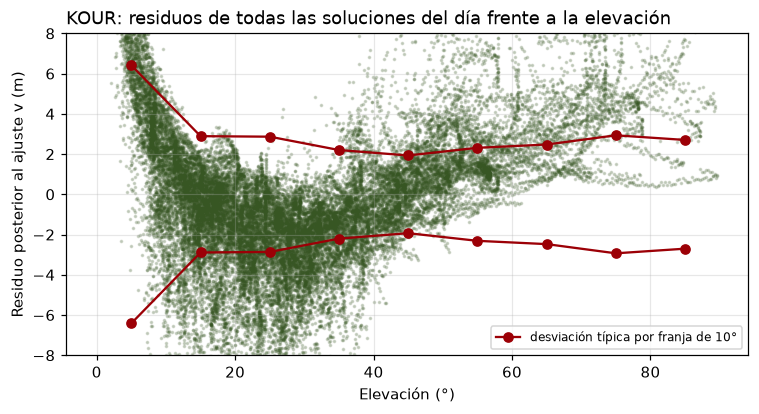

In [17]:
res_el = []                                        # pares (elevación, residuo posterior al ajuste) de todas las soluciones del día
# este diagnóstico usa todos los satélites visibles (no solo los seleccionados):
# así se ve cómo crece el residuo cuando el satélite baja y se justifica la ponderación
for t, g in D.groupby("t"):
    if len(g) < 5 or t in epocas_malas:            # con 4 satélites la solución es exacta y los residuos valen cero
        continue
    S_ = g[["xs", "ys", "zs"]].values
    P_ = g.P1.values + C * g.dts.values
    x_, A_, v_, Q_, h_ = resolver(S_, P_)
    res_el += list(zip(g.el.values, v_))
res_el = np.array(res_el)

# desviación típica de los residuos por franja de 10° de elevación
bins = np.arange(0, 91, 10)
franja = np.digitize(res_el[:, 0], bins)
sd = [res_el[franja == i, 1].std() if (franja == i).sum() > 20 else np.nan for i in range(1, len(bins))]

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.scatter(res_el[:, 0], res_el[:, 1], s=2, color=VERDE, alpha=0.2)
ax.plot(bins[:-1] + 5, sd, "o-", color=ROJO, label="desviación típica por franja de 10°")
ax.plot(bins[:-1] + 5, -np.array(sd), "o-", color=ROJO)
ax.set_ylim(-8, 8)
ax.set_xlabel("Elevación (°)")
ax.set_ylabel("Residuo posterior al ajuste v (m)")
ax.set_title(f"{ESTACION[:4]}: residuos de todas las soluciones del día frente a la elevación", loc="left")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
print("desviación típica del residuo por franja de elevación (m):", {f"{b}-{b+10}°": round(float(s), 2) for b, s in zip(bins[:-1], sd)});

Cada punto es el residuo posterior al ajuste de un satélite en una época, y la línea roja, su desviación típica por franja de 10°. Por debajo de 10° la dispersión se dispara (6,4 m); entre 10° y 30° ronda los 2,9 m, y por encima de 30° baja a unos 2 m. Con el satélite bajo, la señal llega más débil, recorre más atmósfera y sufre más reflexiones cerca de la antena. Por encima de 50° la dispersión vuelve a subir ligeramente, probablemente porque hay menos satélites en esas franjas y porque el residuo mezcla ruido con el sesgo que no explica el modelo.


In [18]:
W = np.diag(np.sin(np.radians(ep.el.values)) ** 2)      # matriz de pesos: sen²(elevación) en la diagonal
xw, Aw, vw, Qw, hw = resolver(S, P, W=W)
print("pesos:", dict(zip(ep.sv, np.diag(W).round(2).tolist())))
print(f"error {HORA} sin pesos: {enu(x).round(2)} m | con pesos sin²(el): {enu(xw).round(2)} m")

# lo mismo en todo el día
filas = []
for t, g in D.groupby("t"):
    g = mejores_por_elevacion(g)                  # la misma selección por elevación
    if len(g) < 4 or t in epocas_malas:
        continue
    S_ = g[["xs", "ys", "zs"]].values
    P_ = g.P1.values + C * g.dts.values
    W_ = np.diag(np.sin(np.radians(g.el.values)) ** 2)
    x_, _, _, _, _ = resolver(S_, P_, W=W_)
    e_ = enu(x_)
    filas.append(dict(t=t, Ew=e_[0], Nw=e_[1], Uw=e_[2]))
solw = pd.DataFrame(filas).set_index("t")

rms_hw = np.sqrt((solw.Ew**2 + solw.Nw**2).mean())
print(f"RMS horizontal del día: sin pesos {rms_h:.2f} m, con pesos {rms_hw:.2f} m | RMS altura: {np.sqrt((sol.U**2).mean()):.1f} -> {np.sqrt((solw.Uw**2).mean()):.1f} m")

pesos: {'G05': 0.21, 'G06': 0.18, 'G11': 0.67, 'G15': 0.52, 'G20': 0.59, 'G21': 0.13, 'G24': 0.42, 'G29': 0.2}
error 12:00:00 sin pesos: [-1.89  1.78 13.87] m | con pesos sin²(el): [-1.63  1.7  13.67] m


RMS horizontal del día: sin pesos 1.99 m, con pesos 1.80 m | RMS altura: 15.7 -> 14.4 m


Con pesos $\sin^2(\text{elevación})$, el error de las 12:00 pasa de (−1,89; +1,78; +13,87) m a (−1,63; +1,70; +13,67) m en Este, Norte y Arriba. En todo el día, el RMS horizontal baja de 1,99 a 1,80 m, y el de altura, de 15,7 a 14,4 m: los satélites bajos, con más ruido y más atmósfera, pesan menos en la solución.


## 11. Propagación de la incertidumbre: covarianza de la solución

> Si cada medida tiene un error aleatorio de desviación típica $\sigma_0$, la solución hereda una incertidumbre que se **calcula**, no se supone:
> $$\boldsymbol{\Sigma}_{\mathbf{x}} = \sigma_0^2\,(\mathbf{A}^{\top}\mathbf{W}\mathbf{A})^{-1} = \sigma_0^2\,\mathbf{Q}$$
> $\mathbf{Q}$ es la **matriz cofactor**: depende solo de la geometría. La diagonal de $\boldsymbol{\Sigma}$ son las varianzas de $X, Y, Z$ y $c\,\delta t_R$; fuera de la diagonal, las covarianzas, que divididas por las desviaciones típicas dan las **correlaciones** entre incógnitas. Girada a ENU, da $\sigma_E, \sigma_N, \sigma_U$ y la **elipse de error** horizontal.


sigma0 = 0.59 m
Q_ENU =
 [[0.472 0.104 0.352 0.236]
 [0.104 0.443 0.359 0.294]
 [0.352 0.359 5.006 2.985]
 [0.236 0.294 2.985 1.921]]
σ_E, σ_N, σ_U, σ_c·δt_R = [0.4  0.39 1.31 0.81] m
correlación entre la altura y el reloj: 0.96
posición de referencia a 7.4 σ en horizontal | error en altura +13.87 m = 10.6 σ_U


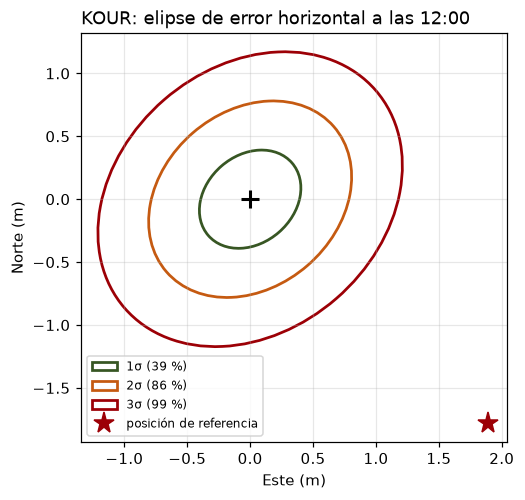

In [19]:
def covarianza_enu(Q):
    """Gira la matriz cofactor Q (en X, Y, Z, c·δt_R) al sistema local (E, N, U, c·δt_R)."""
    T = np.block([[Rm, np.zeros((3, 1))],
                  [np.zeros((1, 3)), np.ones((1, 1))]])
    return T @ Q @ T.T

sigma0 = np.sqrt(v @ v / (n - 4))        # desviación típica estimada de una medida (n − 4 grados de libertad)
Qenu = covarianza_enu(Q)
Sigma = sigma0**2 * Qenu                  # matriz de covarianza de la solución
print(f"sigma0 = {sigma0:.2f} m")
print("Q_ENU =\n", Qenu.round(3))
print("σ_E, σ_N, σ_U, σ_c·δt_R =", np.sqrt(np.diag(Sigma)).round(2), "m")
print(f"correlación entre la altura y el reloj: {Qenu[2, 3] / np.sqrt(Qenu[2, 2] * Qenu[3, 3]):.2f}")
d_elipse = np.sqrt(np.array([E_, N_]) @ np.linalg.inv(Sigma[:2, :2]) @ np.array([E_, N_]))   # distancia a la referencia en unidades de σ
print(f"posición de referencia a {d_elipse:.1f} σ en horizontal | error en altura {U_:+.2f} m = {U_ / np.sqrt(Sigma[2, 2]):.1f} σ_U")

# elipse de error horizontal: ejes = raíces de los autovalores del bloque E-N; orientación = autovector
from matplotlib.patches import Ellipse
autoval, autovec = np.linalg.eigh(Sigma[:2, :2])
angulo = np.degrees(np.arctan2(autovec[1, 1], autovec[0, 1]))
fig, ax = plt.subplots(figsize=(5, 5))
ax.set_aspect("equal")
for k, color, etiqueta in [(1, VERDE, "1σ (39 %)"), (2, NARANJA, "2σ (86 %)"), (3, ROJO, "3σ (99 %)")]:
    ax.add_patch(Ellipse((0, 0), 2 * k * np.sqrt(autoval[1]), 2 * k * np.sqrt(autoval[0]), angle=angulo, fill=False, ec=color, lw=1.8, label=etiqueta))
ax.plot(0, 0, "+", color="k", ms=12, mew=2)                       # la solución
ax.plot(-E_, -N_, "*", color=ROJO, ms=14, label="posición de referencia")
#ax.set_xlim(-3, 3); ax.set_ylim(-3, 3)
ax.set_xlabel("Este (m)"); ax.set_ylabel("Norte (m)")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
ax.set_title(f"{ESTACION[:4]}: elipse de error horizontal a las {HORA[:5]}", loc="left");

A las 12:00, $\hat\sigma_0 = 0{,}59$ m, y las desviaciones típicas de la solución son $\sigma_E = 0{,}40$ m, $\sigma_N = 0{,}39$ m y $\sigma_U = 1{,}31$ m: la altura queda más de tres veces peor determinada que la horizontal. La elipse está inclinada porque los errores en Este y Norte están correlacionados. La posición de referencia (estrella) queda a 7,4 σ de la solución: la covarianza describe solo el ruido aleatorio de las medidas seleccionadas y no incluye ni el sesgo atmosférico ni la exactitud limitada de esa posición de referencia. La altura tampoco: el error de +13,87 m equivale a 10,6 $\sigma_U$. La correlación de 0,96 entre la altura y el reloj explica por qué los dos se mueven juntos (secciones 8 y 9).


## 12. Dilución de la precisión (DOP)

> **Dilución de la precisión (DOP)** — como $\boldsymbol{\Sigma} = \sigma_0^2\mathbf{Q}$, la incertidumbre de la posición es la de una medida multiplicada por un factor que solo depende de la geometría. Con $q$ los elementos de la diagonal de $\mathbf{Q}_{ENU}$ ($q_{tt}$, el del reloj):
> $$\text{GDOP} = \sqrt{q_{EE}+q_{NN}+q_{UU}+q_{tt}},\quad \text{PDOP} = \sqrt{q_{EE}+q_{NN}+q_{UU}},\quad \text{HDOP} = \sqrt{q_{EE}+q_{NN}},\quad \text{VDOP} = \sqrt{q_{UU}},\quad \text{TDOP} = \sqrt{q_{tt}}$$
> No tiene unidades. Se calcula **antes de medir**, solo con las posiciones de los satélites; el DOP crece cuando los satélites se agrupan y se dispara cuando quedan casi en un plano.


In [20]:
def dops(Q):
    """Diluciones de la precisión a partir de la matriz cofactor Q (en X, Y, Z, c·δt_R)."""
    q = np.diag(covarianza_enu(Q))       # varianzas cofactor en E, N, U y c·δt_R
    return dict(GDOP=np.sqrt(q.sum()),
                PDOP=np.sqrt(q[:3].sum()),
                HDOP=np.sqrt(q[:2].sum()),
                VDOP=np.sqrt(q[2]),
                TDOP=np.sqrt(q[3]))

d = dops(Q)
print({k: round(float(valor), 2) for k, valor in d.items()})
print(f"incertidumbre esperada: horizontal HDOP·σ0 = {d['HDOP']*sigma0:.2f} m, vertical VDOP·σ0 = {d['VDOP']*sigma0:.2f} m")

{'GDOP': 2.8, 'PDOP': 2.43, 'HDOP': 0.96, 'VDOP': 2.24, 'TDOP': 1.39}
incertidumbre esperada: horizontal HDOP·σ0 = 0.56 m, vertical VDOP·σ0 = 1.31 m


mejor PDOP 1.75 a las 01:24 (8 satélites) | peor PDOP 3.94 a las 15:25 (8 satélites)


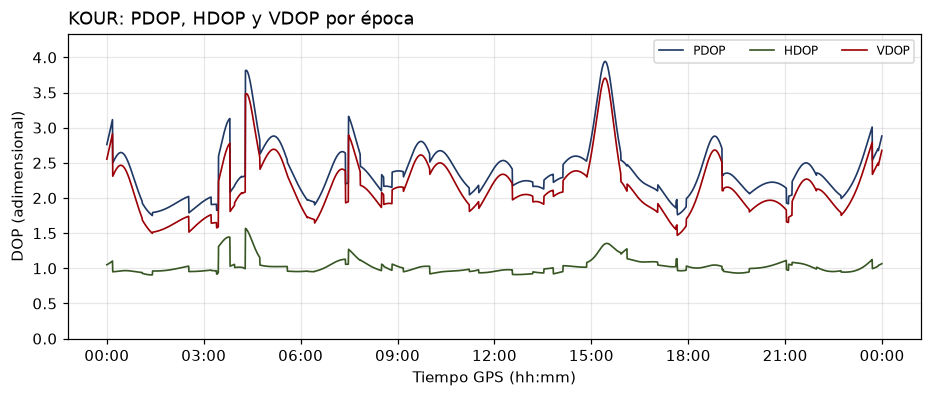

In [21]:
# el DOP solo necesita la geometría: se calcula con A en la posición de referencia, sin resolver nada
filas = []
for t, g in D.groupby("t"):
    g = mejores_por_elevacion(g)                  # el DOP debe describir la geometría que se usa
    if len(g) < 4 or t in epocas_malas:
        continue
    A_, _ = diseno(np.r_[rx, 0.0], g[["xs", "ys", "zs"]].values, g.P1.values)
    d_ = dops(np.linalg.inv(A_.T @ A_))
    d_["t"] = t
    d_["n"] = len(g)
    filas.append(d_)
dop = pd.DataFrame(filas).set_index("t")

fig, ax = plt.subplots(figsize=(10, 3.6))
for nombre, color in [("PDOP", AZUL), ("HDOP", VERDE), ("VDOP", ROJO)]:
    ax.plot(dop.index, dop[nombre], lw=1.1, label=nombre, color=color)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.set_ylim(0, max(3.5, dop.PDOP.max() * 1.1))
ax.set_xlabel("Tiempo GPS (hh:mm)")
ax.set_ylabel("DOP (adimensional)")
ax.legend(ncol=3, fontsize=8)
ax.grid(alpha=0.3)
ax.set_title(f"{ESTACION[:4]}: PDOP, HDOP y VDOP por época", loc="left")

t_mejor, t_peor = dop.PDOP.idxmin(), dop.PDOP.idxmax()
print(f"mejor PDOP {dop.PDOP.min():.2f} a las {t_mejor.strftime('%H:%M')} ({dop.loc[t_mejor, 'n']} satélites) | peor PDOP {dop.PDOP.max():.2f} a las {t_peor.strftime('%H:%M')} ({dop.loc[t_peor, 'n']} satélites)")

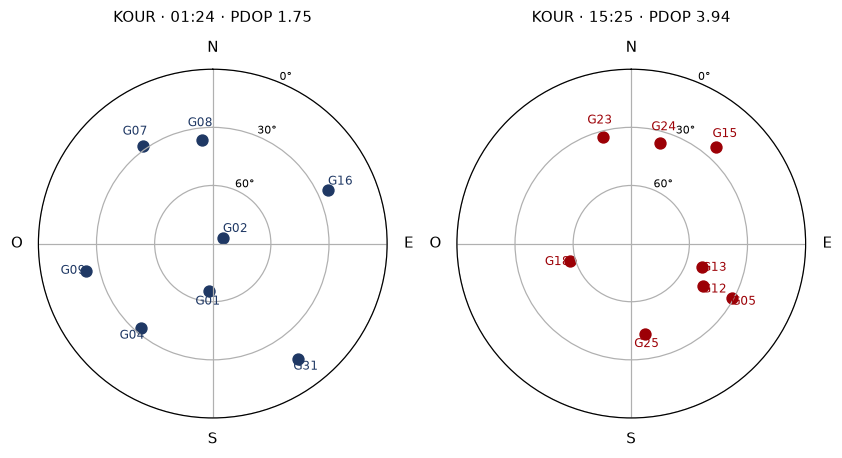

In [22]:
def cielo(ax, g, color, titulo):
    """Dibuja el cielo (acimut y elevación) de los satélites de una época en un eje polar."""
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)
    ax.set_rlim(0, 90)
    ax.set_yticks([0, 30, 60, 90]); ax.set_yticklabels(["90°", "60°", "30°", "0°"], fontsize=7)
    ax.set_xticks(np.radians([0, 90, 180, 270])); ax.set_xticklabels(["N", "E", "S", "O"])
    ax.scatter(np.radians(g.az), 90 - g.el, s=50, color=color)     # el radio es 90° − elevación: el cenit queda en el centro
    for az_, el_, sv_ in zip(g.az, g.el, g.sv):
        ax.text(np.radians(az_), 90 - el_ + 7, sv_, ha="center", fontsize=8, color=color)
    ax.set_title(titulo, fontsize=10, pad=12)

fig = plt.figure(figsize=(9, 4.3))
for k, (t_, color) in enumerate([(t_mejor, AZUL), (t_peor, ROJO)]):
    cielo(fig.add_subplot(1, 2, k + 1, projection="polar"), mejores_por_elevacion(D[D.t == t_]), color, f"{ESTACION[:4]} · {t_.strftime('%H:%M')} · PDOP {dop.loc[t_, 'PDOP']:.2f}")

En el día, el PDOP de la solución con los ocho mejores satélites va de 1,75 a 3,94; el HDOP se mantiene cerca de 1, y el VDOP es casi siempre mayor: la geometría determina peor la altura, porque todos los satélites están por encima del horizonte. El mejor PDOP (01:24) corresponde a un cielo con satélites repartidos en distintas direcciones y elevaciones; el peor (15:25), a una geometría más agrupada. El mayor error en altura del día ocurre a las 21:13 (+28,4 m), no a la hora del peor PDOP: el DOP describe la geometría, no la atmósfera.


## 13. Efecto de la geometría: selección de satélites

Con los once satélites visibles hay 330 maneras de quedarse con cuatro. El mejor cuarteto (uno alto y tres bajos repartidos) tiene un GDOP de 2,5, parecido al 2,8 de los ocho seleccionados por elevación; el peor deja los cuatro casi en un plano y la matriz $\mathbf{A}^{\top}\mathbf{A}$ cerca de ser singular: con las mismas medidas, el error llega a 1 944 km.

La selección por elevación de la sección 1.1 no busca el mejor DOP: busca quitar los satélites bajos, que traen el mayor **retardo atmosférico**, un sesgo que el DOP no ve. Quitar satélites bajos empeora el DOP (sobre todo el VDOP) y, sin embargo, puede reducir el error real en altura (sección 9). Por eso los receptores usan una **máscara de elevación** (típicamente de 5 a 15°) y corrigen la atmósfera con modelos.


In [23]:
import itertools
cuartetos = []
for idx in itertools.combinations(range(n_todos), 4):   # todas las maneras de elegir 4 de los satélites visibles
    idx = list(idx)
    try:
        x4, A4, v4, Q4, _ = resolver(S_todos[idx], P_todos[idx])
        cuartetos.append(dict(svs=" ".join(ep_todos.sv[idx]), GDOP=dops(Q4)["GDOP"], error_3D=np.linalg.norm(enu(x4))))
    except np.linalg.LinAlgError:                       # geometría singular: no hay solución
        pass
cu = pd.DataFrame(cuartetos).sort_values("GDOP")
print("mejor cuarteto:\n", cu.head(3).round(1).to_string(index=False))
print("\npeor cuarteto:\n", cu.tail(3).round(1).to_string(index=False))
print(f"\nGDOP mediano de los {len(cu)} cuartetos:", round(cu.GDOP.median(), 1))


mejor cuarteto:
             svs  GDOP  error_3D
G11 G13 G15 G30   2.5      24.7
G11 G12 G15 G30   2.5      23.9
G11 G13 G29 G30   2.6      26.8

peor cuarteto:
             svs   GDOP  error_3D
G12 G13 G21 G29  636.8     379.0
G05 G12 G13 G29  791.2     441.3
G15 G20 G21 G30 5093.4 1944090.4

GDOP mediano de los 330 cuartetos: 6.6


In [24]:
casos = [("todos los visibles", np.ones(n_todos, bool)),
         (f"mejores {n} por elevación", ep_todos.sv.isin(ep.sv).values),
         ("solo elevación > 25°", ep_todos.el.values > 25),
         ("solo elevación > 40°", ep_todos.el.values > 40)]
for nombre, mascara in casos:
    idx = np.where(mascara)[0]
    xq, Aq, vq, Qq, _ = resolver(S_todos[idx], P_todos[idx])
    dq = dops(Qq)
    print(f"{nombre:<24} n={len(idx):2d}  HDOP {dq['HDOP']:.2f}  VDOP {dq['VDOP']:.2f}  error E,N,U = {enu(xq).round(1)} m")


todos los visibles       n=11  HDOP 0.75  VDOP 1.43  error E,N,U = [-1.5  2.9 23. ] m
mejores 8 por elevación  n= 8  HDOP 0.96  VDOP 2.24  error E,N,U = [-1.9  1.8 13.9] m
solo elevación > 25°     n= 7  HDOP 1.07  VDOP 2.45  error E,N,U = [-1.7  1.9 13.4] m
solo elevación > 40°     n= 4  HDOP 4.14  VDOP 26.35  error E,N,U = [ 0.6  2.9 -2.7] m


Con los once satélites visibles, el VDOP es 1,43 y el error en altura +23,0 m. Al usar los ocho de mayor elevación, el VDOP sube a 2,24, pero el error en altura baja a +13,9 m. Con la máscara de 25° quedan siete satélites: el VDOP sube a 2,45 y la altura queda en +13,4 m. Al quedarse solo con los cuatro satélites por encima de 40°, el VDOP se dispara a 26,35 y el error en altura cambia de signo (−2,7 m): la geometría ya es demasiado pobre y el resultado deja de ser fiable. El DOP predice que la altura empeora al quitar satélites, y con ruido aleatorio así sería; pero aquí el error dominante es el sesgo de la atmósfera, que es mayor en los satélites bajos (sección 9): quitarlos quita sesgo aunque empeore la geometría. En el otro extremo, el peor cuarteto (GDOP 5 093) da 1 944 km de error con las mismas medidas: allí sí manda la geometría.


## 14. Contenido mínimo del reporte de una solución

Una posición sin su incertidumbre no es un resultado. El reporte mínimo de una época:


In [25]:
reporte = {
    "época (tiempo GPS)": str(t0),
    "satélites usados": list(ep.sv),
    "criterio de selección": f"los {n} de mayor elevación entre {n_todos} visibles",
    "pesos": "iguales",
    "X, Y, Z (m)": x[:3].round(3).tolist(),
    "c·δt_R (m)": round(x[3], 3),
    "sigma0 (m)": round(sigma0, 3),
    "residuos (m)": v.round(2).tolist(),
    "σ_E, σ_N, σ_U (m)": np.sqrt(np.diag(Sigma))[:3].round(2).tolist(),
    **{k: round(float(valor), 2) for k, valor in d.items()},
    "error respecto a la posición de referencia E, N, U (m)": enu(x).round(2).tolist(),
    "correcciones aplicadas": "reloj del satélite (af0, af1, af2, relativista, T_GD); instante de emisión con P1; atmósfera: ninguna",
}
for clave, valor in reporte.items():
    print(f"{clave:<52} {valor}")


época (tiempo GPS)                                   2026-09-15 12:00:00
satélites usados                                     ['G05', 'G06', 'G11', 'G15', 'G20', 'G21', 'G24', 'G29']
criterio de selección                                los 8 de mayor elevación entre 11 visibles
pesos                                                iguales
X, Y, Z (m)                                          [3839598.176, -5059579.563, 579959.958]
c·δt_R (m)                                           -38013.891
sigma0 (m)                                           0.587
residuos (m)                                         [-0.53, 0.3, -0.15, 0.8, -0.11, 0.31, -0.46, -0.16]
σ_E, σ_N, σ_U (m)                                    [0.4, 0.39, 1.31]
GDOP                                                 2.8
PDOP                                                 2.43
HDOP                                                 0.96
VDOP                                                 2.24
TDOP                                 

## 15. Preguntas de repaso

Se responden con lo que se vio en los dos cuadernos, `gnss_pseudodistancia.ipynb` (PD) y este (EP), en pocas líneas y con palabras propias. Cada pregunta indica dónde está la respuesta.

**La medida** (PD)

1. ¿Por qué el receptor mide una *pseudo*distancia y no una distancia? Nombre los términos que separan $P$ de $r$. *(PD, sección 0)*
2. Un error de 1 µs en un reloj, ¿cuántos metros de error produce en la distancia? ¿Y uno de 1 ms? *(PD, sección 5)*
3. ¿Por qué el desfase del reloj del receptor es el mismo para todos los satélites de una época, y el del satélite no? ¿Quién conoce cada uno? *(PD, secciones 7 y 8)*

**Separar los términos** (PD)

4. ¿Qué es el residuo de pseudodistancia? ¿Por qué con un solo satélite no se puede saber cuánto es reloj y cuánto atmósfera? *(PD, sección 7)*
5. Para estimar el reloj del receptor se usó la mediana y no la media. Dé las dos razones. ¿Qué habría pasado con la medida errónea de G32 si se hubiera usado la media? *(PD, sección 7; EP, sección 9)*
6. ¿Por qué el residuo crece cuando el satélite baja? ¿Por qué aparecen valores negativos, si la atmósfera siempre retrasa? *(PD, secciones 7 y 9)*
7. ¿Por qué $P2 - P1$ no es cero aunque casi no haya ionosfera? ¿Cómo se sabe que la diferencia que aparece por la mañana es ionosfera y no geometría? *(PD, sección 10)*

**Estimar la posición** (EP)

8. ¿Por qué hacen falta al menos cuatro satélites? En la sección 7 de PD bastaba con conocer la posición: ¿qué incógnitas había allí y cuáles hay aquí? *(EP, sección 1; PD, sección 12)*
9. ¿Qué diferencia hay entre el $O - C$ y el residuo $v$? ¿Cuál de los dos coincide con el residuo de PD? *(EP, secciones 5 y 6)*
10. ¿Por qué hay que iterar? ¿Qué pasa si se parte de un punto muy lejano, como el antípoda de la estación? *(EP, secciones 3 y 7)*

**Interpretar el resultado** (EP)

11. El reloj estimado aquí a las 12:00 es de −38 013,9 m, y en PD, con la posición fija, era otro. ¿Está mal alguno de los dos? ¿Por qué difieren? *(EP, secciones 8, 9 y 11)*
12. ¿Por qué el error en altura sale siempre positivo, y mayor por la tarde y la noche que de madrugada? *(EP, sección 9; PD, sección 10)*
13. La covarianza da $\sigma_U = 1{,}31$ m, pero el error en altura es de 13,9 m. ¿Está mal la covarianza? ¿Qué describe y qué no? *(EP, sección 11)*
14. A las 15:25 se da el peor PDOP del día, pero el mayor error en altura ocurre a las 21:13. ¿Cómo puede ser? *(EP, sección 12)*
15. Quedarse con los ocho satélites más altos empeora el VDOP pero reduce el error en altura. ¿Cómo se explica? *(EP, secciones 1.1 y 13)*

**Para pensar:** si se corrigiera la atmósfera con un modelo, ¿qué esperaría que pase con el error en altura, con $c\,\delta t_R$ y con la diferencia entre el reloj de PD y el de EP?

### Comprobación con otra época (opcional)

Para comprobar con datos alguno de los conceptos anteriores: escriba otra hora en la celda siguiente (por ejemplo, las 06:00:00, de madrugada, o las 21:13:00, por la noche).

In [26]:
# ── ejercicios: cambie la hora ──
t_ej = pd.Timestamp(f"{FECHA} 06:00:00")
ep_ej_todos = D[D.t == t_ej].sort_values("sv").reset_index(drop=True)
ep_ej = mejores_por_elevacion(ep_ej_todos).sort_values("sv").reset_index(drop=True)   # misma selección que la solución
S_ej = ep_ej[["xs", "ys", "zs"]].values           # posiciones de los satélites seleccionados (m)
P_ej = ep_ej.P1.values + C * ep_ej.dts.values     # medidas corregidas P1 + c·δtˢ (m)
print(f"visibles: {len(ep_ej_todos)} | seleccionados: {len(ep_ej)}")
ep_ej[["sv", "el", "az"]].round(1)


visibles: 13 | seleccionados: 8


,sv,el,az
0,G03,24.6,32.9
1,G04,22.6,100.3
2,G06,30.3,299.2
3,G09,33.1,138.2
4,G14,78.6,276.1
5,G17,34.4,2.2
6,G22,58.6,318.7
7,G30,25.6,209.4


- **Preguntas 11 y 12.** Resuelva con `x_ej, A_ej, v_ej, Q_ej, h_ej = resolver(S_ej, P_ej)` y compare `enu(x_ej)` y `x_ej[3]` con los de las 12:00.
- **Pregunta 15.** Quite el satélite más bajo, `idx = (ep_ej.el != ep_ej.el.min()).values`, resuelva con `resolver(S_ej[idx], P_ej[idx])` y compare el VDOP (`dops`) y el error en altura.
- **Preguntas 5 y 9.** Sume 300 m a la medida del satélite más alto, `P_mala = P_ej.copy()` y `P_mala[ep_ej.el.idxmax()] += 300`, resuelva y mire los residuos: ¿el error queda solo en ese satélite?

## Referencias

- Blewitt, G. (1997). *Basics of the GPS Technique: Observation Equations, Software Developments, and Data Processing*. En Teunissen y Kleusberg (eds.), GPS for Geodesy. Springer.
- Leick, A., Rapoport, L. y Tatarnikov, D. (2015). *GPS Satellite Surveying*, 4.ª ed. Wiley.
- Groves, P. D. (2013). *Principles of GNSS, Inertial, and Multisensor Integrated Navigation Systems*, 2.ª ed. Artech House.
- IS-GPS-200, *Navstar GPS Space Segment/Navigation User Segment Interfaces* (gps.gov/technical/icwg).
- Legendre, A.-M. (1805). *Nouvelles méthodes pour la détermination des orbites des comètes* · Gauss, C. F. (1809). *Theoria motus corporum coelestium*.
- IGS, International GNSS Service (igs.org): datos de la estación KOUR.
- `gnss_pseudodistancia.ipynb` (este curso): la ecuación de la pseudodistancia, sus términos y la tabla de datos que usa este cuaderno.